# 26. Three-sensor translation calibration: stochastic learnability and full training

**Question:** Can the existing pooled calibration model learn extrinsic translation corrections for IMU, left LiDAR and right LiDAR when exactly one calibration prior is perturbed per example?

This notebook follows the established KAIST training pipeline from notebook 25, but uses **one translation augmentation distribution** throughout. It initializes from `002.10_fine_coarse`, runs a paired semantic/token sensitivity test, compares the original checkpoint against weights trained for 500 stochastic steps on a small fixed physical set, **restores the original checkpoint**, and optionally trains on the entire KAIST split with a new optimizer. It then compares the source and full-training checkpoints under identical held-out translation priors.

**Scientific caveat:** In the current geometry and with numeric calibration context disabled, IMU translation does not change the model's input tokens. Therefore, a systematic signed IMU translation correction is not identifiable to this architecture. LiDAR translation has a small nonzero token response. IMU is deliberately retained as a negative control, per the experiment design.

The objective supervises **translation only**. Other prediction heads are present but receive no rotation/tau supervision, so do not deploy them from notebook 26 without evaluating forgetting. No raw data, loss source modules, architecture, or generic augmentations need modification.

**Checkpoints:** new run `002.12_translation` is independent. Do not reuse an existing run name or continue stale optimizer state. Run the notebook top-to-bottom on a fresh kernel.

## 1. Imports and repository root

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters

In [2]:
RUN_NAME = "kaist_pooled_calibration_paired_002.12_translation"
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.10_fine_coarse"
RESUME_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 200
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8
RUN_FULL_TRAINING = True

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1
POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

# All prior perturbations target rho only. Keep phi/tau weights zero so this is a clean test.
ROTATION_LOSS_WEIGHT = 0.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 0.0
TRANSLATION_LOSS_SCALE_M = 0.10
PAIR_LOSS_WEIGHT = 0.1
CORRECTION_LOSS_TYPE = "mse"

# Shared true-calibration context stays as in notebook 25: rotation/tau are physically consistent.
TRUE_ROTATION_MAX_DEG = 30.0
TRUE_TIME_OFFSET_MAX_S = 0.030

# Single augmentation distribution, with a hard translation norm <= 20 cm.
TRANSLATION_MAX_M = 0.20
TRANSLATION_DISTRIBUTION = PerturbationDistribution.UNIFORM

# Small-set stochastic stage is diagnostic only; full training restarts from source weights.
TRANSLATION_STOCHASTIC_STEPS = 500
TRANSLATION_STOCHASTIC_BATCH_SIZE = 16
TRANSLATION_STOCHASTIC_LR = 1e-5
TRANSLATION_EVAL_DRAWS = 8
TRANSLATION_REPORT_EVERY = 50
TRANSLATION_SEED = 261234

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source checkpoint not found: {RESUME_CHECKPOINT}")

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Run:", RUN_NAME)
print("Initializing from:", RESUME_CHECKPOINT)
print("Translation prior magnitude: 0–", TRANSLATION_MAX_M, "m")
print("Calibration order:", CALIBRATION_KEYS)

Run: kaist_pooled_calibration_paired_002.12_translation
Initializing from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
Translation prior magnitude: 0– 0.2 m
Calibration order: ('imu', 'lidar', 'lidar_right')


## 3. KAIST sequences, rig calibration, and full data splits

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Shared context augmentation and *one* paired translation prior configuration

In [6]:
# The physical context is augmented once; the two +/- prior branches use identical measurements.
context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False, rotation=None, translation=None, time_offset=None),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

translation_pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=None,
    translation=PerturbationMagnitudeConfig(maximum=TRANSLATION_MAX_M, distribution=TRANSLATION_DISTRIBUTION),
    time_offset=None,
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)

context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
translation_prior_perturber = CalibrationPriorPerturber(translation_pair_prior_config)
print(context_augmentation_config)
print(translation_pair_prior_config)

AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=0.5, probability_by_key={}, rotation=None, translation=None, time_offset=None, one_calibration_per_sample=False, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False), calibration_event=CalibrationEventConfig(enabled=False, event_probability=0.5, event_probability_by_key={}, rotation_probability=0.0, translation_probability=0.0, time_offset_probability=0.0, rotation=None, translation=None, time_offset=None, profile_weights={<TransitionProfile.STEP: 'step'>: 1.0, <TransitionProfile.LINEAR: 'linear'>: 1.0, <TransitionProfile.SMOOTHSTEP: 'smoothstep'>: 1.0}, minimum_transition_duration_s=None, maximum_transition_duration_s=None, minimum_pre_event_fractio

## 5. Unchanged pooled model architecture and window step

In [7]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. Paired construction, semantic checks, and token sensitivity

In [8]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def make_translation_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Perturb rho on exactly one sensor per sample, then create +/- prior branches."""
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration
    _, delta_xi, delta_tau = translation_prior_perturber(true_calibration, generator=generator)
    positive_prior = apply_prior_perturbation(true_calibration, delta_xi, delta_tau)
    negative_prior = apply_prior_perturbation(true_calibration, {key: -value for key, value in delta_xi.items()}, {key: -value for key, value in delta_tau.items()})
    return clone_window_with_calibration(context_window, positive_prior), clone_window_with_calibration(context_window, negative_prior), delta_xi, delta_tau


def correction_target(window: WindowBatch, calibration_key: str):
    target = window.targets[calibration_key]
    state = window.current_calibration[calibration_key]
    return se3_log(target.next_transform @ torch.linalg.inv(state.transform)), target.next_time_offset - state.time_offset


semantic_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=MODEL_DTYPE)
sem_pos, sem_neg, sem_xi, sem_tau = make_translation_paired_windows(semantic_base, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 1))
active_per_sample = torch.zeros(BATCH_SIZE, device=DEVICE, dtype=torch.long)
for key in CALIBRATION_KEYS:
    pos_xi, pos_tau = correction_target(sem_pos, key)
    neg_xi, neg_tau = correction_target(sem_neg, key)
    torch.testing.assert_close(pos_xi, -sem_xi[key], atol=1e-5, rtol=1e-5)
    torch.testing.assert_close(neg_xi, sem_xi[key], atol=1e-5, rtol=1e-5)
    assert torch.max(sem_xi[key][:, :3].abs()).item() < 1e-7
    assert torch.max(sem_tau[key].abs()).item() < 1e-7
    assert torch.max(torch.linalg.vector_norm(sem_xi[key][:, 3:], dim=-1)).item() <= TRANSLATION_MAX_M + 1e-6
    active_per_sample += (torch.linalg.vector_norm(sem_xi[key][:, 3:], dim=-1) > 1e-8).long()
assert torch.all(active_per_sample == 1), 'One translation perturbation must be active per sample'
for stream_key in sem_pos.streams:
    torch.testing.assert_close(sem_pos.streams[stream_key].values, sem_neg.streams[stream_key].values)
print('THREE-SENSOR TRANSLATION PAIR CHECK: PASS')
del sem_pos, sem_neg, sem_xi, sem_tau, semantic_base

THREE-SENSOR TRANSLATION PAIR CHECK: PASS


### Token-sensitivity negative control

Keep the physical measurement streams fixed. Perturb a single calibration's translation by 20 cm, run the actual geometry processor and tokenizer, then measure how much the assigned tokens change. **Exact zero IMU sensitivity would make predicting its signed rho impossible with current numeric context disabled.**

In [9]:
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation

sensitivity_base = window_batch_to(collate_windows([train_dataset[i] for i in np.linspace(0, len(train_dataset) - 1, 8, dtype=int)]), DEVICE, dtype=MODEL_DTYPE)
sensitivity_context = context_augmentation_pipeline(sensitivity_base, generator=make_augmentation_generator(TRANSLATION_SEED + 80)).augmented_window
truth = sensitivity_context.current_calibration
batch_size = next(iter(truth.values())).transform.shape[0]

print('TRANSLATION PRIOR -> TOKEN SENSITIVITY (same physical measurements)')
for key_id, key in enumerate(CALIBRATION_KEYS):
    for axis in range(3):
        xi_plus = {k: torch.zeros(batch_size, 6, dtype=MODEL_DTYPE, device=DEVICE) for k in CALIBRATION_KEYS}
        xi_minus = {k: torch.zeros_like(v) for k, v in xi_plus.items()}
        tau_zero = {k: torch.zeros(batch_size, 1, dtype=MODEL_DTYPE, device=DEVICE) for k in CALIBRATION_KEYS}
        xi_plus[key][:, 3 + axis] = TRANSLATION_MAX_M
        xi_minus[key][:, 3 + axis] = -TRANSLATION_MAX_M
        cal_plus = apply_prior_perturbation(truth, xi_plus, tau_zero)
        cal_minus = apply_prior_perturbation(truth, xi_minus, tau_zero)
        window_plus = clone_window_with_calibration(sensitivity_context, cal_plus)
        window_minus = clone_window_with_calibration(sensitivity_context, cal_minus)
        tokens_plus = tokenizer(geometry_processor(window_plus.streams, window_plus.metadata, window_plus.current_calibration), None)
        tokens_minus = tokenizer(geometry_processor(window_minus.streams, window_minus.metadata, window_minus.current_calibration), None)
        mask = tokens_plus.token_mask & (tokens_plus.calibration_ids == key_id)
        delta = tokens_plus.x[..., :MEASUREMENT_DIM][mask] - tokens_minus.x[..., :MEASUREMENT_DIM][mask]
        rms = float(torch.sqrt(torch.mean(delta.square())).cpu())
        print(f'{key:12s} rho_{"xyz"[axis]}: token RMS change = {rms:.8e}')
print('Pooler/head numeric calibration context:', model.pooler.calibration_context_dim, model.head.config.calibration_context_dim)
del sensitivity_base, sensitivity_context, truth
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

TRANSLATION PRIOR -> TOKEN SENSITIVITY (same physical measurements)
imu          rho_x: token RMS change = 0.00000000e+00
imu          rho_y: token RMS change = 0.00000000e+00
imu          rho_z: token RMS change = 0.00000000e+00
lidar        rho_x: token RMS change = 1.46976393e-03
lidar        rho_y: token RMS change = 1.46639370e-03
lidar        rho_z: token RMS change = 4.96970839e-04
lidar_right  rho_x: token RMS change = 1.50664535e-03
lidar_right  rho_y: token RMS change = 1.50728924e-03
lidar_right  rho_z: token RMS change = 5.92751370e-04
Pooler/head numeric calibration context: 0 0


## 7. Translation-only paired objective and evaluation metrics

In [10]:
def translation_paired_objective(positive_window, positive_output, negative_window, negative_output):
    '''Same MSE regular + pair-difference formulation, restricted to rho for this diagnostic.'''
    regular_terms, pair_terms = [], []

    for key in CALIBRATION_KEYS:
        positive_target_xi, _ = correction_target(positive_window, key)
        negative_target_xi, _ = correction_target(negative_window, key)
        positive_target = positive_target_xi[:, 3:]
        negative_target = negative_target_xi[:, 3:]
        positive_pred = positive_output.predictions[key].delta_xi[:, 3:]
        negative_pred = negative_output.predictions[key].delta_xi[:, 3:]

        regular_terms.append(0.5 * (F.mse_loss(positive_pred / TRANSLATION_LOSS_SCALE_M, positive_target / TRANSLATION_LOSS_SCALE_M) + F.mse_loss(negative_pred / TRANSLATION_LOSS_SCALE_M, negative_target / TRANSLATION_LOSS_SCALE_M)))
        pair_terms.append(F.mse_loss((positive_pred - negative_pred) / TRANSLATION_LOSS_SCALE_M, (positive_target - negative_target) / TRANSLATION_LOSS_SCALE_M))

    loss_regular = torch.stack(regular_terms).mean()
    loss_pair = torch.stack(pair_terms).mean()
    return loss_regular + PAIR_LOSS_WEIGHT * loss_pair, loss_regular, loss_pair


def translation_stochastic_evaluate(base_window, *, seed, draws=TRANSLATION_EVAL_DRAWS):
    '''Fixed-seed active-only evaluation; the same priors are regenerated for each checkpoint.'''
    generator = make_augmentation_generator(seed)
    sums = {key: dict(n=0, active_error_cm=0.0, zero_baseline_cm=0.0, pair_error_cm=0.0, pair_target_cm=0.0, pair_prediction_cm=0.0, pair_dot=0.0, pair_target_sq=0.0, inactive_n=0, inactive_false_cm=0.0) for key in CALIBRATION_KEYS}
    model.eval()

    with torch.inference_mode():
        for _ in range(draws):
            positive_window, negative_window, _, _ = make_translation_paired_windows(base_window, generator=generator)
            positive_output = window_step(positive_window).model_output
            negative_output = window_step(negative_window).model_output
            active_count = torch.zeros(base_window.current_calibration[CALIBRATION_KEYS[0]].transform.shape[0], dtype=torch.int32, device=DEVICE)

            for key in CALIBRATION_KEYS:
                positive_target_xi, _ = correction_target(positive_window, key)
                negative_target_xi, _ = correction_target(negative_window, key)
                target_positive = positive_target_xi[:, 3:]
                target_negative = negative_target_xi[:, 3:]
                pred_positive = positive_output.predictions[key].delta_xi[:, 3:]
                pred_negative = negative_output.predictions[key].delta_xi[:, 3:]
                active = torch.linalg.vector_norm(target_positive, dim=-1) > 1e-6
                active_count += active.to(torch.int32)
                n = int(active.sum().item())
                inactive = ~active

                stats = sums[key]
                stats['n'] += n
                stats['inactive_n'] += int(inactive.sum().item())
                stats['inactive_false_cm'] += 50.0 * (torch.linalg.vector_norm(pred_positive[inactive], dim=-1).sum().item() + torch.linalg.vector_norm(pred_negative[inactive], dim=-1).sum().item())
                if n == 0:
                    continue

                stats['active_error_cm'] += 50.0 * (torch.linalg.vector_norm(pred_positive[active] - target_positive[active], dim=-1).sum().item() + torch.linalg.vector_norm(pred_negative[active] - target_negative[active], dim=-1).sum().item())
                stats['zero_baseline_cm'] += 50.0 * (torch.linalg.vector_norm(target_positive[active], dim=-1).sum().item() + torch.linalg.vector_norm(target_negative[active], dim=-1).sum().item())
                target_pair = target_positive[active] - target_negative[active]
                pred_pair = pred_positive[active] - pred_negative[active]
                stats['pair_error_cm'] += 100.0 * torch.linalg.vector_norm(pred_pair - target_pair, dim=-1).sum().item()
                stats['pair_target_cm'] += 100.0 * torch.linalg.vector_norm(target_pair, dim=-1).sum().item()
                stats['pair_prediction_cm'] += 100.0 * torch.linalg.vector_norm(pred_pair, dim=-1).sum().item()
                stats['pair_dot'] += (pred_pair * target_pair).sum().item()
                stats['pair_target_sq'] += target_pair.square().sum().item()

            if not torch.all(active_count == 1):
                raise AssertionError('Expected exactly one active translation calibration in every sample')

    results = {}
    for key, s in sums.items():
        if s['n'] == 0:
            raise AssertionError(f'No active translation examples for {key}; increase TRANSLATION_EVAL_DRAWS')
        results[key] = dict(
            n=s['n'],
            active_mae_cm=s['active_error_cm'] / s['n'],
            zero_baseline_cm=s['zero_baseline_cm'] / s['n'],
            pair_mae_cm=s['pair_error_cm'] / s['n'],
            pair_target_cm=s['pair_target_cm'] / s['n'],
            pair_prediction_cm=s['pair_prediction_cm'] / s['n'],
            pair_gain=s['pair_dot'] / max(s['pair_target_sq'], 1e-15),
            inactive_false_cm=s['inactive_false_cm'] / max(s['inactive_n'], 1),
        )
    return results


def print_translation_comparison(before, after, title):
    print('\n' + '=' * 117)
    print(title)
    print('sensor         N   zero cm   source active cm   trained active cm   change    source gain   trained gain   source false cm   trained false cm')
    for key in CALIBRATION_KEYS:
        a, b = before[key], after[key]
        change = 100.0 * (b['active_mae_cm'] / max(a['active_mae_cm'], 1e-12) - 1.0)
        print(f"{key:12s} {a['n']:4d} {a['zero_baseline_cm']:9.2f} {a['active_mae_cm']:18.2f} {b['active_mae_cm']:19.2f} {change:+8.1f}% {a['pair_gain']:13.3f} {b['pair_gain']:14.3f} {a['inactive_false_cm']:17.2f} {b['inactive_false_cm']:18.2f}")
    print('Gain = projection of the predicted +/- difference onto the true +/- difference (1 is ideal; 0 means no pair response).')
    print('Pair-difference MAE [cm], source -> trained: ' + ' | '.join(f"{k}: {before[k]['pair_mae_cm']:.2f} -> {after[k]['pair_mae_cm']:.2f}" for k in CALIBRATION_KEYS))

## 8. Stochastic 500-step diagnostic: source vs trained, fixed train and unseen validation windows

This stage changes the model **in memory only**. It records errors before and after on identical fixed synthetic perturbations, then restores the original `002.10` parameters in a `finally` block. It does not write checkpoints. It reports **active-only** translation MAE, the zero-correction baseline, pair response, and spurious updates on inactive sensors.

step    1/500 | regular=0.12850, pair=0.51398
step   50/500 | regular=0.15890, pair=0.63559
step  100/500 | regular=0.15045, pair=0.60176
step  150/500 | regular=0.16766, pair=0.67049
step  200/500 | regular=0.06261, pair=0.24990
step  250/500 | regular=0.15193, pair=0.60710
step  300/500 | regular=0.18680, pair=0.74574
step  350/500 | regular=0.13718, pair=0.54820
step  400/500 | regular=0.17631, pair=0.70431
step  450/500 | regular=0.15523, pair=0.61758
step  500/500 | regular=0.16519, pair=0.65307

STOCHASTIC TRANSLATION: FIXED TRAIN PHYSICAL WINDOWS
sensor         N   zero cm   source active cm   trained active cm   change    source gain   trained gain   source false cm   trained false cm
imu            46     10.71              10.71               10.71     +0.0%         0.000          0.000              0.01               0.07
lidar          44     11.03              11.03               10.78     -2.2%        -0.000          0.032              0.02               0.63
lidar_right 

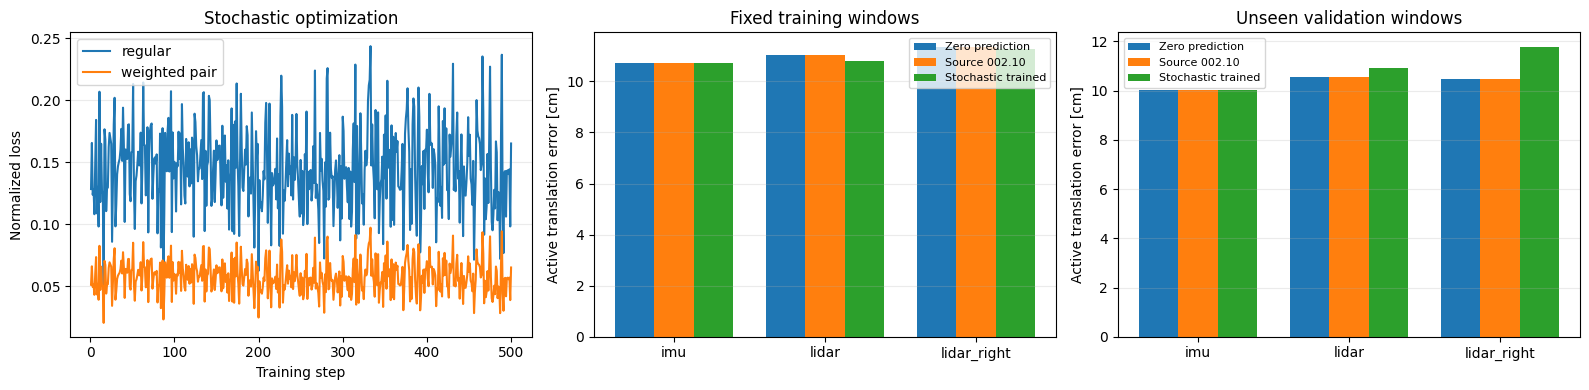


Original model weights restored. Stochastic training did not alter your saved checkpoint.


In [15]:
# One fixed set of physical windows for training and a disjoint held-out set for evaluation.
translation_train_indices = np.linspace(0, len(train_dataset) - 1, TRANSLATION_STOCHASTIC_BATCH_SIZE, dtype=int)
translation_val_indices = np.linspace(0, len(val_dataset) - 1, TRANSLATION_STOCHASTIC_BATCH_SIZE, dtype=int)
translation_train_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in translation_train_indices]), DEVICE, dtype=MODEL_DTYPE)
translation_val_base = window_batch_to(collate_windows([val_dataset[int(i)] for i in translation_val_indices]), DEVICE, dtype=MODEL_DTYPE)

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(RESUME_CHECKPOINT)

original_training_mode = model.training
load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
original_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

try:
    eval_train_before = translation_stochastic_evaluate(translation_train_base, seed=TRANSLATION_SEED + 1)
    eval_val_before = translation_stochastic_evaluate(translation_val_base, seed=TRANSLATION_SEED + 2)
    optimizer_translation = torch.optim.AdamW(model.parameters(), lr=TRANSLATION_STOCHASTIC_LR, weight_decay=0.0)
    training_generator = make_augmentation_generator(TRANSLATION_SEED)
    translation_history = []

    for step in range(1, TRANSLATION_STOCHASTIC_STEPS + 1):
        model.train()
        positive_window, negative_window, _, _ = make_translation_paired_windows(translation_train_base, generator=training_generator)
        optimizer_translation.zero_grad(set_to_none=True)
        positive_output = window_step(positive_window).model_output
        negative_output = window_step(negative_window).model_output
        loss, regular_loss, pair_loss = translation_paired_objective(positive_window, positive_output, negative_window, negative_output)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        optimizer_translation.step()
        translation_history.append((step, regular_loss.item(), pair_loss.item()))
        if step == 1 or step % TRANSLATION_REPORT_EVERY == 0:
            print(f'step {step:4d}/{TRANSLATION_STOCHASTIC_STEPS} | regular={regular_loss.item():.5f}, pair={pair_loss.item():.5f}')

    eval_train_after = translation_stochastic_evaluate(translation_train_base, seed=TRANSLATION_SEED + 1)
    eval_val_after = translation_stochastic_evaluate(translation_val_base, seed=TRANSLATION_SEED + 2)
    print_translation_comparison(eval_train_before, eval_train_after, 'STOCHASTIC TRANSLATION: FIXED TRAIN PHYSICAL WINDOWS')
    print_translation_comparison(eval_val_before, eval_val_after, 'STOCHASTIC TRANSLATION: HELD-OUT VALIDATION PHYSICAL WINDOWS')

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    history_array = np.asarray(translation_history)
    axes[0].plot(history_array[:, 0], history_array[:, 1], label='regular')
    axes[0].plot(history_array[:, 0], PAIR_LOSS_WEIGHT * history_array[:, 2], label='weighted pair')
    axes[0].set_title('Stochastic optimization')
    axes[0].set_xlabel('Training step')
    axes[0].set_ylabel('Normalized loss')
    axes[0].legend()

    for ax, before, after, title in ((axes[1], eval_train_before, eval_train_after, 'Fixed training windows'), (axes[2], eval_val_before, eval_val_after, 'Unseen validation windows')):
        x = np.arange(len(CALIBRATION_KEYS))
        ax.bar(x - 0.26, [before[k]['zero_baseline_cm'] for k in CALIBRATION_KEYS], width=0.26, label='Zero prediction')
        ax.bar(x, [before[k]['active_mae_cm'] for k in CALIBRATION_KEYS], width=0.26, label='Source 002.10')
        ax.bar(x + 0.26, [after[k]['active_mae_cm'] for k in CALIBRATION_KEYS], width=0.26, label='Stochastic trained')
        ax.set_xticks(x, CALIBRATION_KEYS)
        ax.set_ylabel('Active translation error [cm]')
        ax.set_title(title)
        ax.legend(fontsize=8)

    for ax in axes:
        ax.grid(True, axis='y', alpha=0.25)
    fig.tight_layout()
    plt.show()
finally:
    # The stochastic stage is diagnostic only. Full training must begin from the original source checkpoint.
    model.load_state_dict(original_model_state)
    model.zero_grad(set_to_none=True)
    model.train(original_training_mode)
    for variable_name in ('optimizer_translation', 'positive_window', 'negative_window', 'positive_output', 'negative_output', 'loss', 'regular_loss', 'pair_loss', 'original_model_state'):
        if variable_name in globals():
            del globals()[variable_name]
    import gc
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    print('\nOriginal model weights restored. Stochastic training did not alter your saved checkpoint.')

**Read the stochastic gate carefully:** it is possible for the aggregate loss to decrease while IMU translation stays at its zero-prediction baseline. The held-out validation comparison is particularly important. Proceed to full training as a separate experiment; stochastic weights have already been restored.

## 9. Full-dataset epoch runner

In [11]:
def run_translation_epoch(loader, *, training: bool, pair_generator: torch.Generator, global_step: int):
    model.train(training)
    metric_sums = {}
    n_samples = 0
    start_time = time.perf_counter()
    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_index, base_window in enumerate(loader):
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
            positive_window, negative_window, _, _ = make_translation_paired_windows(base_window, generator=pair_generator)
            if training:
                optimizer.zero_grad(set_to_none=True)
            positive_output = window_step(positive_window).model_output
            negative_output = window_step(negative_window).model_output
            loss, regular_loss, pair_loss = translation_paired_objective(positive_window, positive_output, negative_window, negative_output)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
                global_step += 1
            batch_size = next(iter(base_window.streams.values())).values.shape[0]
            for name, val in (('loss_total', loss), ('loss_regular', regular_loss), ('loss_pair', pair_loss)):
                metric_sums[name] = metric_sums.get(name, 0.0) + float(val.detach()) * batch_size
            for key in CALIBRATION_KEYS:
                pos_t, _ = correction_target(positive_window, key)
                neg_t, _ = correction_target(negative_window, key)
                pos_p = positive_output.predictions[key].delta_xi[:, 3:]
                neg_p = negative_output.predictions[key].delta_xi[:, 3:]
                active = torch.linalg.vector_norm(pos_t[:, 3:], dim=-1) > 1e-7
                # Both +/- branches contribute; summing branch MAE preserves active subset semantics.
                for mask, name in ((active, 'active'), (~active, 'inactive')):
                    count = int(mask.sum().item())
                    metric_sums[f'{key}/{name}_n'] = metric_sums.get(f'{key}/{name}_n', 0) + count
                    if count:
                        pair_branch_error = (torch.linalg.vector_norm(pos_p[mask] - pos_t[mask, 3:], dim=-1).sum() + torch.linalg.vector_norm(neg_p[mask] - neg_t[mask, 3:], dim=-1).sum()) * 50.0
                        metric_sums[f'{key}/{name}_sum_cm'] = metric_sums.get(f'{key}/{name}_sum_cm', 0.0) + float(pair_branch_error.detach())
                        if name == 'active':
                            baseline = (torch.linalg.vector_norm(pos_t[mask, 3:], dim=-1).sum() + torch.linalg.vector_norm(neg_t[mask, 3:], dim=-1).sum()) * 50.0
                            metric_sums[f'{key}/zero_sum_cm'] = metric_sums.get(f'{key}/zero_sum_cm', 0.0) + float(baseline.detach())
            n_samples += batch_size
            if training and PRINT_EVERY_BATCHES > 0 and (batch_index + 1) % PRINT_EVERY_BATCHES == 0:
                print(f'batch {batch_index + 1}/{len(loader)} | regular={float(regular_loss.detach()):.5f}')
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    metrics = {k: metric_sums[k] / n_samples for k in ('loss_total', 'loss_regular', 'loss_pair')}
    for key in CALIBRATION_KEYS:
        for tag in ('active','inactive'):
            cnt = max(metric_sums.get(f'{key}/{tag}_n', 0), 1)
            metrics[f'{key}/{tag}_mae_cm'] = metric_sums.get(f'{key}/{tag}_sum_cm', 0.0) / cnt
        metrics[f'{key}/zero_mae_cm'] = metric_sums.get(f'{key}/zero_sum_cm', 0.0) / max(metric_sums.get(f'{key}/active_n', 0),1)
    metrics['epoch_time_s'] = time.perf_counter() - start_time
    return metrics, global_step


def print_translation_epoch(label, metrics):
    print(f'{label:18s} regular={metrics["loss_regular"]:.5f} pair={metrics["loss_pair"]:.5f}')
    for key in CALIBRATION_KEYS:
        print(f'  {key:12s} active={metrics[f"{key}/active_mae_cm"]:8.3f} cm | zero={metrics[f"{key}/zero_mae_cm"]:8.3f} cm | inactive false={metrics[f"{key}/inactive_mae_cm"]:8.3f} cm')

## 10. New run, experiment snapshot, checkpoint saving

In [12]:
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
METRICS_PATH = RUN_DIR / 'metrics.jsonl'

EXPERIMENT_SNAPSHOT = {
    'run_name': RUN_NAME,
    'architecture': 'PooledCalibrationModel',
    'model_config': model_config,
    'windowing_config': windowing_config,
    'rig_calibration': rig_calibration,
    'measurement_dim': MEASUREMENT_DIM,
    'calibration_keys': CALIBRATION_KEYS,
    'sequence_split': {'train': tuple(TRAIN_NAMES), 'validation': tuple(VAL_NAMES), 'test': tuple(TEST_NAMES)},
    'initialization_checkpoint': str(RESUME_CHECKPOINT),
    'pair_sampling_strategy': 'single_translation_distribution_one_calibration_per_sample',
    'pair_prior_config': translation_pair_prior_config,
    'context_augmentation_config': context_augmentation_config,
    'pair_translation_max_m': TRANSLATION_MAX_M,
    'pair_rotation_max_rad': None,
    'pair_time_offset_max_s': None,
    'correction_loss_type': CORRECTION_LOSS_TYPE,
    'translation_loss_scale_m': TRANSLATION_LOSS_SCALE_M,
    'rotation_loss_weight': ROTATION_LOSS_WEIGHT,
    'translation_loss_weight': TRANSLATION_LOSS_WEIGHT,
    'time_offset_loss_weight': TIME_OFFSET_LOSS_WEIGHT,
    'pair_loss_weight': PAIR_LOSS_WEIGHT,
    'checkpoint_selection_metric': 'loss_regular',
    'numeric_calibration_context_in_pooler': False,
    'numeric_calibration_context_in_head': False,
    'translation_only_supervision': True,
    'seeds': {'random': RANDOM_SEED, 'train_pair': TRAIN_PAIR_SEED, 'validation_pair': VALIDATION_PAIR_SEED, 'test_pair': TEST_PAIR_SEED},
}

LOGGER_EXPERIMENT_SNAPSHOT = {
    'run_name': RUN_NAME,
    'calibration_keys': list(CALIBRATION_KEYS),
    'initialization_checkpoint': str(RESUME_CHECKPOINT),
    'pair_sampling_strategy': EXPERIMENT_SNAPSHOT['pair_sampling_strategy'],
    'translation_max_cm': 100 * TRANSLATION_MAX_M,
    'translation_loss_scale_cm': 100 * TRANSLATION_LOSS_SCALE_M,
    'rotation_loss_weight': ROTATION_LOSS_WEIGHT,
    'translation_loss_weight': TRANSLATION_LOSS_WEIGHT,
    'time_offset_loss_weight': TIME_OFFSET_LOSS_WEIGHT,
    'pair_loss_weight': PAIR_LOSS_WEIGHT,
    'checkpoint_selection_metric': 'loss_regular',
}

# Full training restarts from the source checkpoint with a NEW optimizer and schedule.
load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)
train_pair_generator = make_augmentation_generator(TRAIN_PAIR_SEED)
start_epoch = 0
global_step = 0
best_validation_loss = float('inf')
print('Training source:', RESUME_CHECKPOINT)
print('Target checkpoint:', BEST_CHECKPOINT_PATH)

Training source: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
Target checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.12_translation/best.pt


## 11. Full KAIST training (optional)

In [19]:
torch.cuda.empty_cache()

In [16]:
history = []
if RUN_FULL_TRAINING:
    with MetricsLogger(METRICS_PATH, append=False) as logger:
        logger.log_config(model_config, name='model_config')
        logger.log_config(context_augmentation_config, name='context_augmentation_config')
        logger.log_config(translation_pair_prior_config, name='pair_prior_config')
        logger.log_config(LOGGER_EXPERIMENT_SNAPSHOT, name='experiment')
        for epoch in range(start_epoch, NUM_EPOCHS):
            print('\n' + '=' * 72)
            print(f'Epoch {epoch + 1}/{NUM_EPOCHS}')
            train_metrics, global_step = run_translation_epoch(train_loader, training=True, pair_generator=train_pair_generator, global_step=global_step)
            val_generator = make_augmentation_generator(VALIDATION_PAIR_SEED)  # same perturbations every epoch
            val_metrics, _ = run_translation_epoch(val_loader, training=False, pair_generator=val_generator, global_step=0)
            scheduler.step(val_metrics['loss_regular'])
            lr = optimizer.param_groups[0]['lr']
            history.append({'epoch': epoch+1, 'lr': lr, **{f'train/{k}': v for k,v in train_metrics.items()}, **{f'val/{k}': v for k,v in val_metrics.items()}})
            logger.log_metrics({**train_metrics, 'learning_rate': lr}, split='train', epoch=epoch+1, step=global_step)
            logger.log_metrics(val_metrics, split='validation', epoch=epoch+1, step=global_step)
            print_translation_epoch('train', train_metrics)
            print_translation_epoch('validation', val_metrics)
            print(f'lr={lr:.3e}')
            if val_metrics['loss_regular'] < best_validation_loss:
                best_validation_loss = val_metrics['loss_regular']
                save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator}, extra_state={'best_validation_loss': best_validation_loss, 'experiment': EXPERIMENT_SNAPSHOT})
                print('Saved new best checkpoint.')
            if (epoch+1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch+1 == NUM_EPOCHS:
                save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator}, extra_state={'best_validation_loss': best_validation_loss, 'experiment': EXPERIMENT_SNAPSHOT})
                print('Saved last checkpoint.')
            gc.collect()
            if DEVICE.type == 'cuda': 
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print('Full training disabled; stochastic comparison remains available.')


Epoch 1/200
train              regular=0.14927 pair=0.59706
  imu          active=   4.760 cm | zero=   4.754 cm | inactive false=   0.012 cm
  lidar        active=   3.736 cm | zero=   3.713 cm | inactive false=   0.035 cm
  lidar_right  active=   4.305 cm | zero=   4.282 cm | inactive false=   0.037 cm
validation         regular=0.14085 pair=0.56333
  imu          active=   5.197 cm | zero=   5.191 cm | inactive false=   0.014 cm
  lidar        active=   3.165 cm | zero=   3.139 cm | inactive false=   0.036 cm
  lidar_right  active=   3.907 cm | zero=   3.881 cm | inactive false=   0.034 cm
lr=1.000e-05

Epoch 2/200
train              regular=0.14954 pair=0.59812
  imu          active=   4.355 cm | zero=   4.349 cm | inactive false=   0.011 cm
  lidar        active=   4.140 cm | zero=   4.115 cm | inactive false=   0.040 cm
  lidar_right  active=   4.272 cm | zero=   4.243 cm | inactive false=   0.047 cm
validation         regular=0.14084 pair=0.56332
  imu          active=   5.196 

KeyboardInterrupt: 

## 12. Checkpoint metadata and learning curves

Snapshot verified: best.pt epoch 6
Snapshot verified: last.pt epoch 18


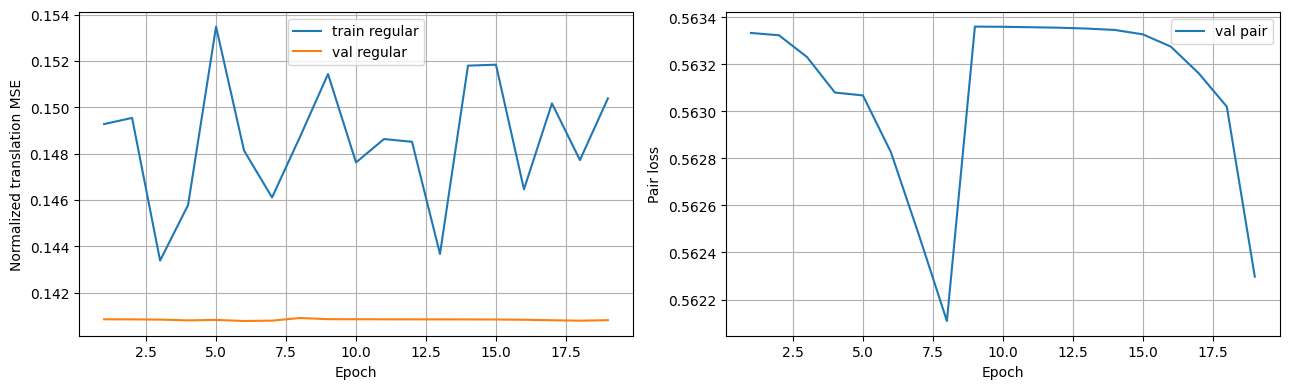

In [17]:
from obscalib.training.checkpoint import read_training_checkpoint
for path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH):
    if not path.is_file():
        print('Missing (not yet saved):', path)
        continue
    data = read_training_checkpoint(path, map_location='cpu')
    experiment = (data.get('extra_state') or {}).get('experiment')
    assert isinstance(experiment, dict) and experiment['run_name'] == RUN_NAME
    assert experiment['pair_prior_config'].one_calibration_per_sample
    assert experiment['pair_prior_config'].rotation is None and experiment['pair_prior_config'].time_offset is None
    print('Snapshot verified:', path.name, 'epoch', data.get('epoch'))
    del data

if history:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot([r['epoch'] for r in history], [r['train/loss_regular'] for r in history], label='train regular')
    axes[0].plot([r['epoch'] for r in history], [r['val/loss_regular'] for r in history], label='val regular')
    axes[1].plot([r['epoch'] for r in history], [r['val/loss_pair'] for r in history], label='val pair')
    for ax in axes:
        ax.grid(True); ax.legend(); ax.set_xlabel('Epoch')
    axes[0].set_ylabel('Normalized translation MSE')
    axes[1].set_ylabel('Pair loss')
    fig.tight_layout(); plt.show()

## 13. Matched held-out test: source `002.10` versus full-trained `002.12`

Uses the entire 699-window test split, with the **same deterministic paired perturbations** for both checkpoints. The table reports active-only rho correction MAE, zero predictor, and inactive false updates for all three sensors. Only load `002.12` if a best checkpoint actually exists.

source_002.10      regular=0.13466 pair=0.53862
  imu          active=   4.025 cm | zero=   4.018 cm | inactive false=   0.012 cm
  lidar        active=   3.599 cm | zero=   3.587 cm | inactive false=   0.022 cm
  lidar_right  active=   4.116 cm | zero=   4.101 cm | inactive false=   0.019 cm
trained_002.12     regular=0.13453 pair=0.53780
  imu          active=   4.036 cm | zero=   4.018 cm | inactive false=   0.032 cm
  lidar        active=   3.647 cm | zero=   3.587 cm | inactive false=   0.067 cm
  lidar_right  active=   4.142 cm | zero=   4.101 cm | inactive false=   0.093 cm


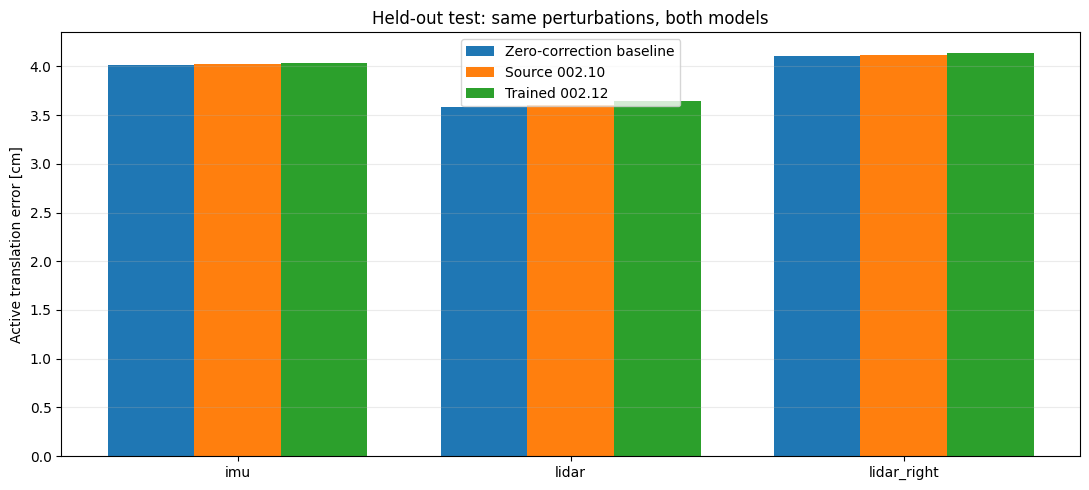

In [20]:
if BEST_CHECKPOINT_PATH.is_file():
    comparison = {}
    for label, path in (('source_002.10', RESUME_CHECKPOINT), ('trained_002.12', BEST_CHECKPOINT_PATH)):
        load_training_checkpoint(path, model=model, map_location=DEVICE, restore_rng_state=False)
        metrics, _ = run_translation_epoch(test_loader, training=False, pair_generator=make_augmentation_generator(TEST_PAIR_SEED), global_step=0)
        comparison[label] = metrics
        print_translation_epoch(label, metrics)
    keys = CALIBRATION_KEYS
    x = np.arange(len(keys))
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - 0.26, [comparison['source_002.10'][f'{k}/zero_mae_cm'] for k in keys], width=.26, label='Zero-correction baseline')
    ax.bar(x, [comparison['source_002.10'][f'{k}/active_mae_cm'] for k in keys], width=.26, label='Source 002.10')
    ax.bar(x + 0.26, [comparison['trained_002.12'][f'{k}/active_mae_cm'] for k in keys], width=.26, label='Trained 002.12')
    ax.set_xticks(x, keys); ax.set_ylabel('Active translation error [cm]'); ax.set_title('Held-out test: same perturbations, both models')
    ax.grid(True, axis='y', alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
else:
    print('No 002.12 best checkpoint found; the stochastic source-vs-trained diagnostic above is already available.')

## 14. Held-out per-axis translation scatter and pair-difference scatter

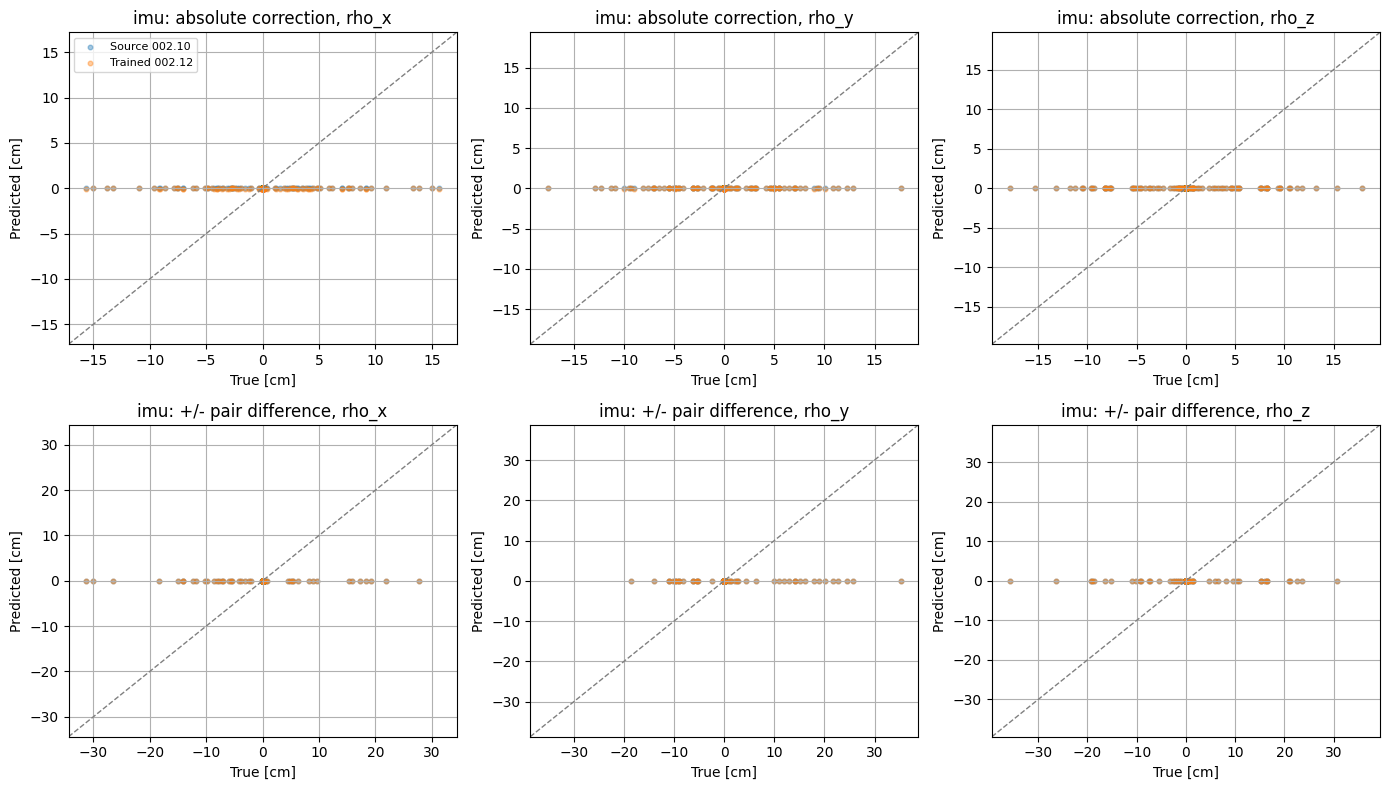

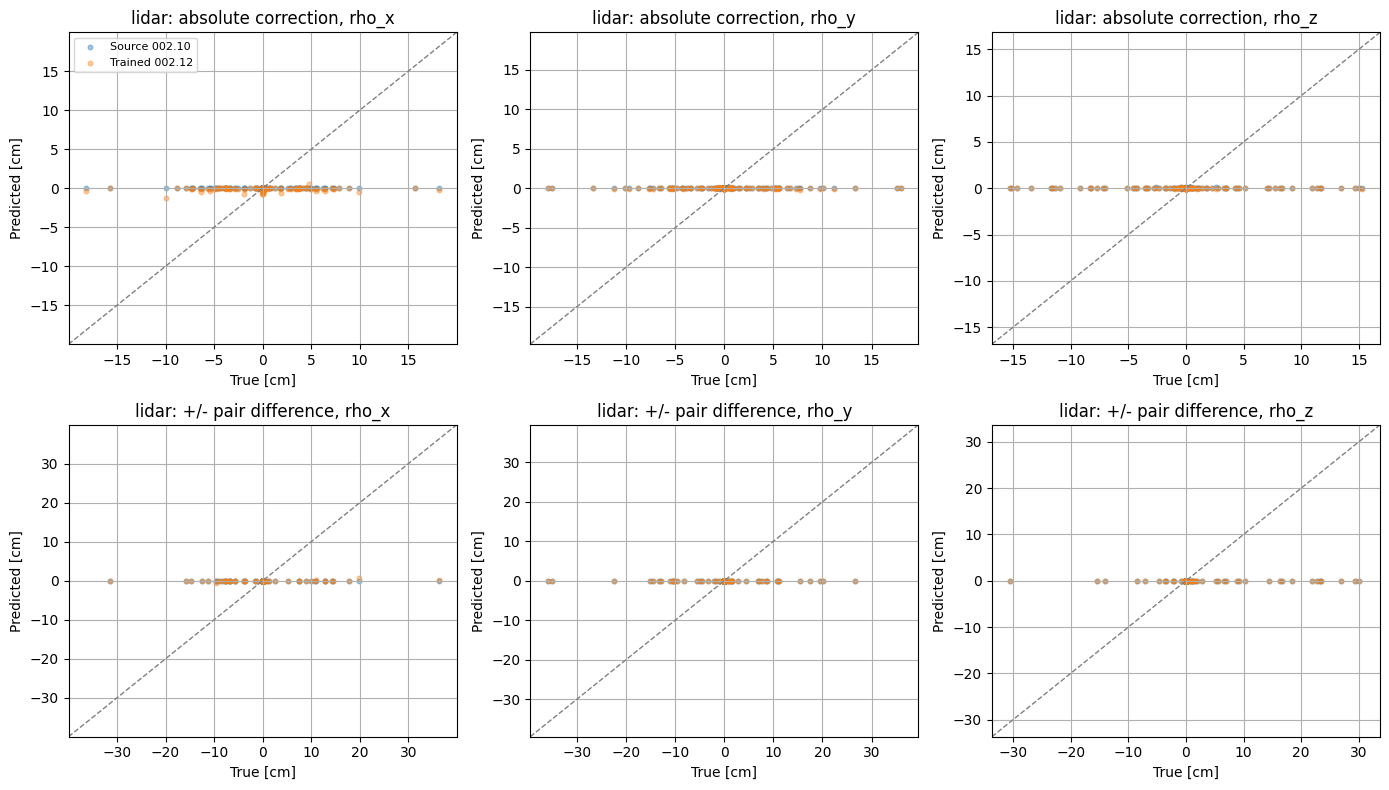

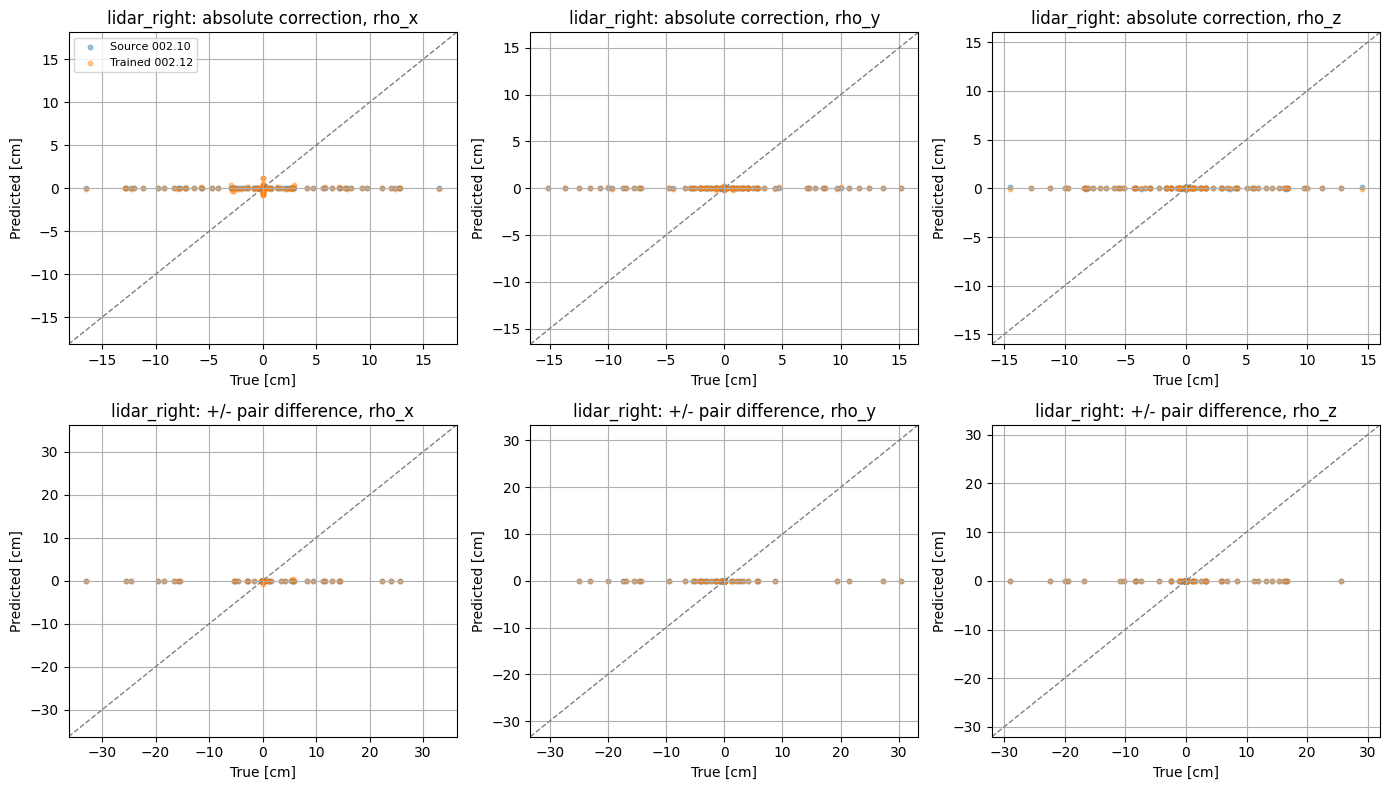

In [21]:
def collect_translation_predictions(dataset, *, checkpoint, indices, seed, batch_size=8):
    load_training_checkpoint(checkpoint, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    output = {k: {'true': [], 'pred': [], 'pair_true': [], 'pair_pred': []} for k in CALIBRATION_KEYS}
    generator = make_augmentation_generator(seed)
    with torch.inference_mode():
        for start in range(0, len(indices), batch_size):
            batch = window_batch_to(collate_windows([dataset[int(i)] for i in indices[start:start+batch_size]]), DEVICE, dtype=MODEL_DTYPE)
            wp, wn, _, _ = make_translation_paired_windows(batch, generator=generator)
            op, on = window_step(wp).model_output, window_step(wn).model_output
            for k in CALIBRATION_KEYS:
                tp = correction_target(wp, k)[0][:, 3:]
                tn = correction_target(wn, k)[0][:, 3:]
                pp = op.predictions[k].delta_xi[:, 3:]
                pn = on.predictions[k].delta_xi[:, 3:]
                output[k]['true'].append(torch.cat((tp, tn)).cpu().numpy() * 100)
                output[k]['pred'].append(torch.cat((pp, pn)).cpu().numpy() * 100)
                output[k]['pair_true'].append((tp-tn).cpu().numpy() * 100)
                output[k]['pair_pred'].append((pp-pn).cpu().numpy() * 100)
    return {k: {name: np.concatenate(chunks) for name, chunks in fields.items()} for k, fields in output.items()}

if BEST_CHECKPOINT_PATH.is_file():
    plot_indices = np.unique(np.linspace(0, len(test_dataset)-1, 128, dtype=int))
    source_vis = collect_translation_predictions(test_dataset, checkpoint=RESUME_CHECKPOINT, indices=plot_indices, seed=VISUALIZATION_PAIR_SEED)
    trained_vis = collect_translation_predictions(test_dataset, checkpoint=BEST_CHECKPOINT_PATH, indices=plot_indices, seed=VISUALIZATION_PAIR_SEED)
    for k in CALIBRATION_KEYS:
        fig, axes = plt.subplots(2, 3, figsize=(14, 8))
        for row, (truth_key, pred_key, row_title) in enumerate((('true', 'pred', 'absolute correction'), ('pair_true','pair_pred','+/- pair difference'))):
            for axis in range(3):
                ax = axes[row, axis]
                a = source_vis[k][truth_key][:, axis]
                b = source_vis[k][pred_key][:, axis]
                c = trained_vis[k][pred_key][:, axis]
                ax.scatter(a, b, s=11, alpha=.4, label='Source 002.10')
                ax.scatter(a, c, s=11, alpha=.4, label='Trained 002.12')
                lim = np.max(np.abs(np.r_[a, b, c])) * 1.1 + 1e-6
                ax.plot([-lim, lim], [-lim, lim], '--', color='grey', linewidth=1)
                ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
                ax.set_title(f'{k}: {row_title}, rho_{"xyz"[axis]}')
                ax.set_xlabel('True [cm]'); ax.set_ylabel('Predicted [cm]'); ax.grid(True)
                if row == 0 and axis == 0: ax.legend(fontsize=8)
        fig.tight_layout(); plt.show()
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

## 15. Interpretation

- **Strongest positive result:** after stochastic/full training, active LiDAR translation MAE becomes meaningfully smaller than the zero-correction baseline **on unseen sequences**, and pair-difference gain moves toward 1.
- **IMU rho negative control:** if IMU tokens are invariant to signed rho, stochastic training can overfit the fixed 16 windows or infer a spurious prior, but cannot systematically recover the signed perturbation on new samples. A change in the network input is required for identifiability.
- **Don't interpret the untrained output heads:** this notebook supervises only translation. Rotation and tau outputs may drift during fine-tuning. Keep `002.10` as the production/local-calibration baseline.
- **Next structural experiment if needed:** supply physically motivated motion-consistency / lever-arm features or explicit calibration context and evaluate full vs marginalized observability, instead of merely broadening rho magnitude.